# 花卉照片的真实 DeepDream
固定 ImageNet 预训练 GoogLeNet，只优化输入图片。可按顺序运行下面各单元。第一次运行会下载约 50 MB 的模型权重。依赖：torch、torchvision、numpy、pillow、scikit-learn。

## 1. 定义网络与像素优化
核心计算是隐藏层激活的平方均值。对图片求梯度，沿增加激活的方向更新像素；随机平移减少固定网格纹理，逐层放大图像以积累细节。下面的 `dream` 函数包含完整循环。

In [1]:
import argparse
import hashlib
import json
from pathlib import Path
import time

ROOT = Path.cwd()
if not (ROOT/'original.jpg').exists():
    raise FileNotFoundError('请从 deepdream 项目目录打开 Notebook')

import numpy as np
from PIL import Image
import torch
import torch.nn.functional as F
from torchvision.models import googlenet, GoogLeNet_Weights


def digest(model):
    result = hashlib.sha256()
    for p in model.parameters():
        result.update(p.detach().cpu().numpy().tobytes())
    return result.hexdigest()


def make_features(layer, device):
    model = googlenet(weights=GoogLeNet_Weights.IMAGENET1K_V1).eval()
    names = ['conv1', 'maxpool1', 'conv2', 'conv3', 'maxpool2',
             'inception3a', 'inception3b', 'maxpool3', 'inception4a',
             'inception4b', 'inception4c', 'inception4d', 'inception4e']
    features = torch.nn.Sequential(*(getattr(model, name) for name in names[:names.index(layer)+1]))
    features.to(device).eval().requires_grad_(False)
    return features


def to_image(x):
    pixels = x.detach().clamp(0, 1).cpu()[0].permute(1, 2, 0).numpy()
    return Image.fromarray(np.uint8(np.round(255*pixels)))


def dream(image, features, steps, sizes, outdir, device):
    original = torch.tensor(np.asarray(image).copy(), dtype=torch.float32, device=device).permute(2, 0, 1)[None]/255
    learned_detail = torch.zeros_like(original)
    frames = [dict(file='original.jpg', step=0, octave=0, loss=None)]
    count = 0
    rng = np.random.default_rng(42)
    for octave, size in enumerate(sizes, 1):
        h = round(image.height*size/image.width)
        base = F.interpolate(original, size=(h, size), mode='bilinear', align_corners=False)
        x = (base + F.interpolate(learned_detail, size=(h, size), mode='bilinear', align_corners=False)).clamp(0,1)
        for iteration in range(1, steps+1):
            x = x.detach().requires_grad_(True)
            shift = tuple(int(v) for v in rng.integers(-8,9,size=2))
            jittered = torch.roll(x, shifts=shift, dims=(-2,-1))
            # Torchvision GoogLeNet's built-in input transform reduces to RGB [-1,1].
            activation = features(2*jittered-1)
            objective = activation.square().mean()
            grad, = torch.autograd.grad(objective, x)
            assert torch.isfinite(grad).all()
            with torch.no_grad():
                x = (x + 0.012*grad/(grad.abs().mean()+1e-8)).clamp(0,1)
            count += 1
            if iteration % 5 == 0 or iteration == steps:
                filename = f'{outdir.name}/frame-{count:03d}.jpg'
                to_image(x).resize((768,512), Image.Resampling.LANCZOS).save(ROOT/filename, quality=92)
                frames.append(dict(file=filename, step=count, octave=octave, loss=float(objective.detach().cpu())))
                print(f'{outdir.name}: step {count}, size {size}, activation energy {frames[-1]["loss"]:.4f}', flush=True)
        learned_detail = x.detach()-base
    to_image(x).save(outdir/'final.png')
    return frames




## 2. 查看原图，冻结网络

In [2]:
from IPython.display import display
torch.manual_seed(42)
torch.set_num_threads(4)
device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
image = Image.open(ROOT/'original.jpg').convert('RGB')
display(image)
features = make_features('inception4d', device)
before = digest(features)

<PIL.Image.Image image mode=RGB size=640x427 at 0x11DF59160>


## 3. 运行 175 步优化
每个分辨率运行 35 步，共五个尺度。输出图片和中间帧写入 `notebook-run`。

notebook-run: step 5, size 200, activation energy 0.4407
notebook-run: step 10, size 200, activation energy 0.5724
notebook-run: step 15, size 200, activation energy 0.8078
notebook-run: step 20, size 200, activation energy 0.9179
notebook-run: step 25, size 200, activation energy 1.0494
notebook-run: step 30, size 200, activation energy 1.1516
notebook-run: step 35, size 200, activation energy 1.1290
notebook-run: step 40, size 280, activation energy 0.9064
notebook-run: step 45, size 280, activation energy 1.0179
notebook-run: step 50, size 280, activation energy 1.1917
notebook-run: step 55, size 280, activation energy 1.3026
notebook-run: step 60, size 280, activation energy 1.4789
notebook-run: step 65, size 280, activation energy 1.5580
notebook-run: step 70, size 280, activation energy 1.5991
notebook-run: step 75, size 392, activation energy 0.9230
notebook-run: step 80, size 392, activation energy 1.2252
notebook-run: step 85, size 392, activation energy 1.4643
notebook-run: s

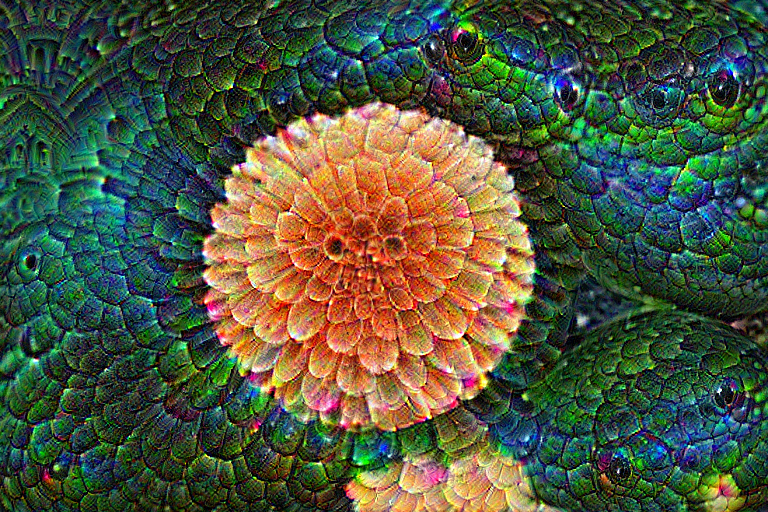

In [3]:
outdir=ROOT/'notebook-run'
outdir.mkdir(exist_ok=True)
frames=dream(image, features, 35, [200,280,392,548,768], outdir, device)
assert digest(features)==before
display(Image.open(outdir/'final.png'))
print('验证通过：网络权重保持不变。')

## 图片与方法来源
照片为 scikit-learn 内置 flower.jpg 示例，源链接：https://www.flickr.com/photos/vultilion/6056698931/ ，许可 CC BY 2.0；本示例对照片进行了 DeepDream 修改。模型为 torchvision GoogLeNet_Weights.IMAGENET1K_V1。方法参考 Google 的 Inceptionism（2015）：https://research.google/blog/inceptionism-going-deeper-into-neural-networks/ 。本例使用 GoogLeNet，多层 Inception 结构；它比玩具网络复杂，但具备产生这些视觉纹理所需的预训练特征。